# 1. Simulated TDI data and custom gravitational-wave sources

**Goal:** generate interferometer measurements, form second-generation TDI,
and compute detector responses to five different types of source waveform.

The first example contains **one GB + one MBHB** signals, as well as  acceleration, readout and
laser-frequency noises. 
The second example computes **one day** signal-only
X2 responses for EMRI, stellar-mass BBH, MBHB, GB and SGWB.

In [1]:
%matplotlib inline
# Paths and plotting defaults only; the scientific workflow is below.
from tutorial_tools.common import DATA, OUTPUT, ORBIT, DAY, load_arrays, inner
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

## 1. Set up the orbit and the two sources

In [2]:
from Triangle.Constants import L_nominal, F_LASER
from Triangle.Orbit import Orbit
from Triangle.GW import Initialize_GW_response
from Triangle.Offset import OffsetFunctions
from Triangle.Noise import InstrumentalPSDs
from Triangle.Interferometer import Interferometers, TPStoTCB
from Triangle.TDI import TDI

np.random.seed(20261106)
orbit = Orbit(OrbitDir=str(ORBIT))
fs, duration = 4., 5*DAY
gb_parameters = dict(
    A=3.39879192e-22, f0=0.00984299, fdot0=4.31168731e-16,
    phase0=0.79960729, inclination=2.29680093,
    longitude=4.50950561, latitude=-0.30076513, psi=3.08152927)
mbhb_parameters = dict(
    chirp_mass=400000., mass_ratio=0.3640815267051051,
    spin_1z=0.7899406190510447, spin_2z=0.015424596359292053,
    coalescence_time=3., coalescence_phase=3.2535342675592966,
    luminosity_distance=56039.10941463517, inclination=1.4495086550199021,
    longitude=3.032776598141215, latitude=-1.1817968279048852, psi=0.2409146690555858)
gw_gb = Initialize_GW_response(signal_type="GB", parameters=gb_parameters, orbit=orbit)
gw_mbhb = Initialize_GW_response(signal_type="MBHB", parameters=mbhb_parameters,
                               orbit=orbit, approximant="SEOBNRv4_opt")

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No pyseobnr.
no cupy 
initializing responses.


100%|██████████| 1/1 [00:00<00:00, 3236.35it/s]


responses initialized.
initializing responses.


100%|██████████| 1/1 [00:00<00:00,  8.36it/s]

responses initialized.


## 2. Simulate interferometer measurements
Laser noise is switched on here so that the raw science measurements can be
inspected before TDI  and the cancellation can be seen afterwards.


In [3]:
ifo = Interferometers(
    size=int(duration*fs), fsample=fs, time_frame="ProperTime", orbit_class=orbit,
    offset_class=OffsetFunctions(laser_flag=False, clock_flag=False),
    noise_class=InstrumentalPSDs(L=L_nominal), gw_class=gw_gb+gw_mbhb,
    acc_noise=True, ro_noise=True, laser_noise=True, clock_noise=False,
    ob_noise=False, bl_noise=False, op_noise=False, ranging_noise=False,
    modulation_noise=False, fplan=None, order=31, pool=None, clean_memory=True)
ifo.SimulateInterferometers()
measurements = TPStoTCB(ifo.OutputMeasurements(mode="decomposed"),
                        orbit_class=orbit, order=31)
ifo.clean()
print("Measurement families:", sorted(measurements))


Measurement families: ['a', 'b', 'fsample', 'ltt', 'ref_c', 'ref_sb', 'sci_c', 'sci_sb', 'time', 'tm_c']


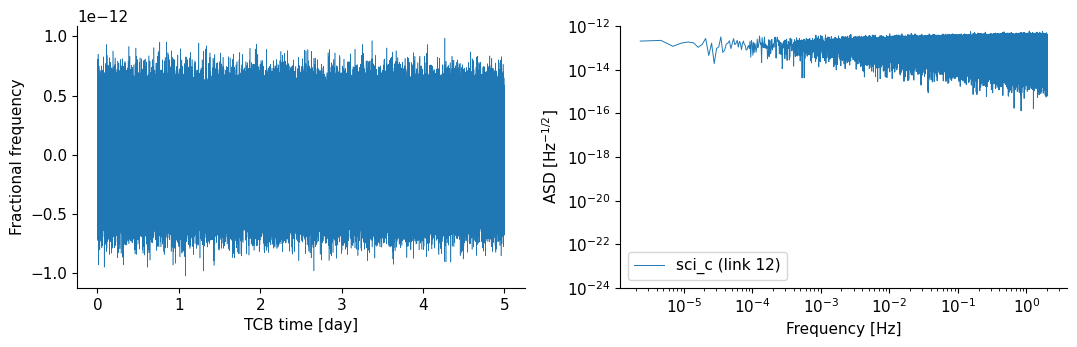

In [4]:
from Triangle.FFTTools import PSD_window

# Before TDI: one carrier-band science link, in fractional frequency.
sci_c = measurements["sci_c"]["12"]/F_LASER
t_sci = measurements["time"]["1"]/DAY

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(t_sci, sci_c, lw=0.4)
ax[0].set(xlabel="TCB time [day]", ylabel="Fractional frequency")
for y, name in [(sci_c, "sci_c (link 12)")]:
    f, psd = PSD_window(y, fs, 1, window_type="tukey",
                        window_args_dict=dict(alpha=0.1))
    ax[1].loglog(f, np.sqrt(psd), lw=0.7, label=name)
ax[1].set(xlabel="Frequency [Hz]", ylabel=r"ASD [Hz$^{-1/2}$]",
          ylim=(1e-24, 1e-12))
ax[1].legend()
plt.tight_layout()


## 3. Form $\xi$, $\eta$ and TDI

In [5]:
tdi = TDI(measurements=measurements, delays=measurements["ltt"], fsample=fs, order=31)
tdi.CalculateXi(doppler=True)
tdi.CalculateEta(doppler=True)
tdi.FastMichelson(doppler=True, channel="AET")
edge = int(1500*fs)
aet = np.array([tdi.measurements[c][edge:-edge]/F_LASER for c in ("A2", "E2", "T2")])
time_days = (edge+np.arange(aet.shape[1]))/fs/DAY
assert np.isfinite(aet).all() and aet.shape[0] == 3

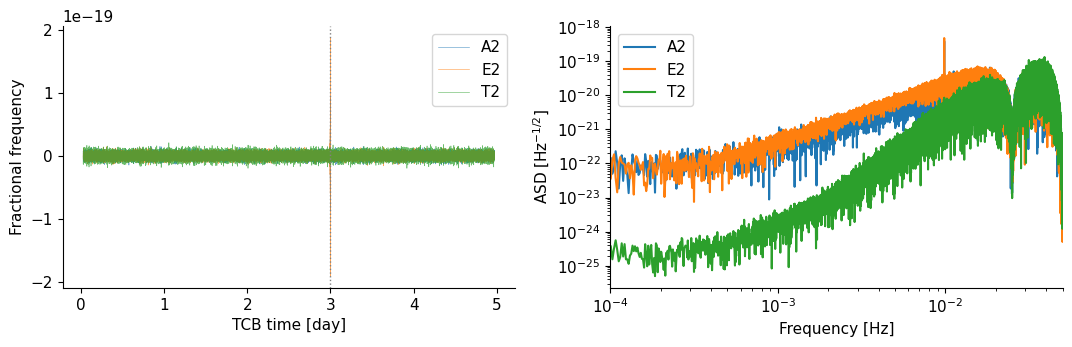

In [6]:
from Triangle.Data import downsampling
from Triangle.FFTTools import PSD_window

# Anti-alias then decimate the TDI channels: 4 Hz -> 0.1 Hz.
# downsampling() applies a Kaiser-FIR low-pass before every-`factor`-th sample.
# [240, 0.02, 0.08] is Triangle's nominal 4 Hz -> 0.1 Hz setting (240 dB
# stopband, transition band 0.02-0.08 Hz around the new Nyquist of 0.05 Hz).
factor = int(round(fs/0.1))                      # 40
aafilter = [240, 0.02, 0.08]
aet_ds = np.array([downsampling(y, fs, factor, aafilter)[100:-100] for y in aet])
fs_ds = fs/factor                                # 0.1 Hz
time_ds = time_days[::factor][100:-100]          # drop the filter transients

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for y, name in zip(aet_ds, ("A2", "E2", "T2")):
    ax[0].plot(time_ds, y, lw=0.45, alpha=0.7, label=name)
    f, psd = PSD_window(y, fs_ds, 1, window_type="tukey",
                        window_args_dict=dict(alpha=0.1))
    ax[1].loglog(f, np.sqrt(psd), label=name)
ax[0].axvline(3, color="gray", ls=":", lw=1)
ax[0].set(xlabel="TCB time [day]", ylabel="Fractional frequency")
ax[1].set(xlabel="Frequency [Hz]", ylabel=r"ASD [Hz$^{-1/2}$]",
          xlim=(1e-4, fs_ds/2))
for panel in ax: panel.legend()
plt.tight_layout()
np.savez_compressed(OUTPUT/"mixed_gb_mbhb_tdi.npz", time_days=time_ds, aet=aet_ds)


## 4. TDI responses of 5 source types 


In [7]:
from Triangle.GW import GeneralTDIResponse, General_Injection, GB_Injection, MBHB_Injection
dt, start, padding = 2., 4.25*DAY, 2000.
t = np.arange(start-padding, start+DAY+padding+dt/2, dt)
keep = (t >= start) & (t <= start+DAY)
sky = dict(longitude=3., latitude=-0.6, psi=0.4)
tdi_response = GeneralTDIResponse(  # callable: (parameters, waveform) -> X2 series
    orbit=orbit, Pstring=GeneralTDIResponse.X2_strings, tcb_times=t,
    use_gpu=False, drop_points=1, linear_interp=False)
responses = {}  # source name -> computed X2 time series


### EMRI: sampled source polarisations → TDI
These are cropped input $h_+=h_1$, $h_\times=-h_2$ from the repository's
`Demo_EMRI_waveform_data.npz`.

In [8]:
emri = load_arrays("emri_polarisations.npz")
waveform = General_Injection(t_data=emri["time_s"], hp_data=emri["hp"], hc_data=emri["hc"])
responses["EMRI"] = tdi_response(parameters=sky, waveform_generator=waveform)[keep]
print("Computed EMRI response:", len(responses["EMRI"]), "samples")


Computed EMRI response: 43201 samples


### Stellar-mass BBH: write a custom waveform
A leading-order circular inspiral with $m_1=m_2=30\,M_\odot$ at 10 kpc,
$f=12$ mHz at day 5 and $\iota=1.1$ rad. This is an inspiral illustration,
not a complete inspiral–merger–ringdown model.
$h_+=a(1+\cos^2\iota)\cos\Phi$, $h_\times=2a\cos\iota\sin\Phi$.

In [9]:
from Triangle.Constants import G, C, MSUN, MPC
mc, f0 = (30*30)**(3/5)/(30+30)**(1/5), 0.012
fdot = 96/5*np.pi**(8/3)*(G*mc*MSUN/C**3)**(5/3)*f0**(11/3)
tau = 3*f0/(8*fdot)
loga = np.log1p(-(t-5*DAY)/tau)
frequency = f0*np.exp(-3/8*loga)
phase = 0.8+16*np.pi*f0*tau/5*(-np.expm1(5/8*loga))
amplitude = 2*(G*mc*MSUN)**(5/3)*(np.pi*frequency)**(2/3)/(C**4*0.01*MPC)
hp = amplitude*(1+np.cos(1.1)**2)*np.cos(phase)
hc = 2*amplitude*np.cos(1.1)*np.sin(phase)
waveform = General_Injection(t_data=t, hp_data=hp, hc_data=hc)
responses["Stellar-mass BBH"] = tdi_response(parameters=sky, waveform_generator=waveform)[keep]


### MBHB and GB: use the native waveform generators

In [10]:
# Both generators return (t, h_+ + i h_x), the tuple format GeneralTDIResponse
# expects, so each is passed directly and takes its full parameter dict.
# The gallery window is fixed at days 4.25-5.25, so the MBHB is placed at day 5.
p_mbhb = {**mbhb_parameters, **sky, "coalescence_time": 5.}
responses["MBHB"] = tdi_response(
    parameters=p_mbhb,
    waveform_generator=MBHB_Injection(
        approx_method="IMRPhenomT", buffer=True))[keep]

p_gb = dict(A=1.52072235e-22, f0=0.00261367, fdot0=3.34732748e-17,
            phase0=3.42918555, inclination=1.5166699, **sky)
responses["GB"] = tdi_response(parameters=p_gb, waveform_generator=GB_Injection(use_gpu=False))[keep]


### SGWB: sum independent sky directions
Draw independent polarisation realisations in 48 HEALPix directions and
sum their TDI responses. We use $\Omega_{\rm GW}=10^{-11}(f/f_*)^{-1}$
between 2 and 30 mHz, $f_*=3.162$ mHz. This coarse discretisation
demonstrates the interface; convergence with sky resolution is not tested.
No instrumental noise is included in this five-source gallery.

In [11]:
import healpy as hp
from Triangle.Constants import H0
from Triangle.Noise import GeneralNoise

def polarisation_psd(f):
    f = np.asarray(f)
    psd = np.zeros_like(f)
    band = (f >= 0.002) & (f <= 0.030)
    psd[band] = (3*H0**2/(4*np.pi**2)*1e-11*(f[band]/3.162e-3)**(-1)
                 /f[band]**3*1e6/MPC**2)
    return psd

np.random.seed(20261106)
noise = GeneralNoise(polarisation_psd)
theta, longitude = hp.pix2ang(2, np.arange(48))
background = np.zeros(keep.sum())
for th, lon in zip(theta, longitude):
    plus = noise(fsample=1/dt, size=len(t))/np.sqrt(48)
    cross = noise(fsample=1/dt, size=len(t))/np.sqrt(48)
    waveform = General_Injection(t_data=t, hp_data=plus, hc_data=cross)
    direction = dict(longitude=lon, latitude=np.pi/2-th, psi=0.)
    background += tdi_response(parameters=direction, waveform_generator=waveform)[keep]
responses["SGWB"] = background
print("Computed all five responses")


Computed all five responses


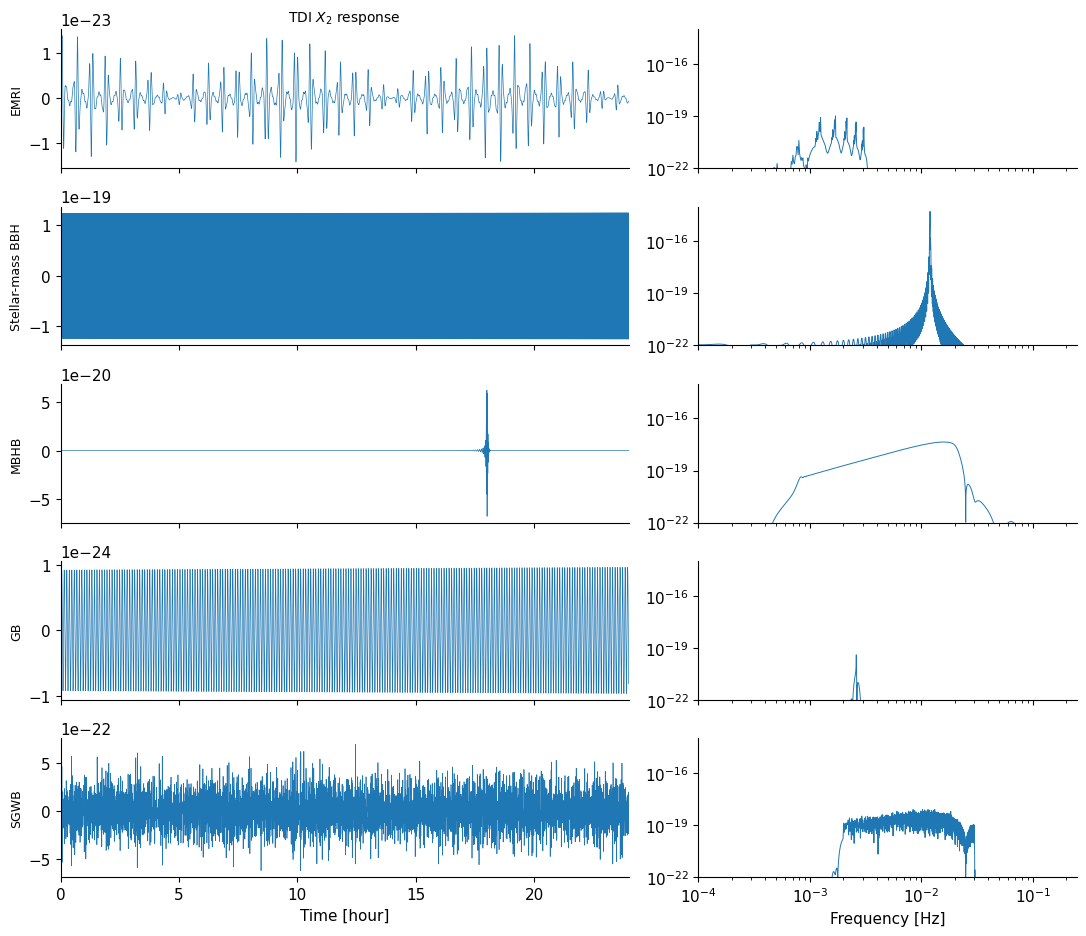

In [12]:
from Triangle.FFTTools import FFT_window

fig, axes = plt.subplots(5, 2, figsize=(11, 9.5), sharex="col",
                         gridspec_kw=dict(width_ratios=[1.5, 1]))
for (name, y), (ax_t, ax_f) in zip(responses.items(), axes):
    assert np.isfinite(y).all() and np.max(abs(y)) > 0
    ax_t.plot((t[keep]-start)/3600, y, lw=0.5)        # raw amplitude
    ax_t.set_ylabel(name, fontsize=9)
    f, yf = FFT_window(y, 1/dt, window_type="tukey",
                       window_args_dict=dict(alpha=0.1))
    ax_f.loglog(f, np.abs(yf), lw=0.7)  
    ax_f.set(ylim=(1e-22, 1e-14))
axes[0, 0].set_title(r"TDI $X_2$ response", fontsize=10)
# axes[0, 1].set_title(r"$|\tilde y(f)|$ from FFT_window, Tukey $\alpha=0.25$",
                    #  fontsize=10)
# axes[0, 1].legend(fontsize=7, frameon=False, loc="lower right")
axes[-1, 0].set(xlabel="Time [hour]", xlim=(0, 24))
axes[-1, 1].set(xlabel="Frequency [Hz]", xlim=(1e-4, 0.25))
plt.tight_layout()
np.savez_compressed(OUTPUT/"five_source_responses.npz", time_s=t[keep], **responses)
